# Caili Discourse Analysis — public demonstration

**Dingyu Zhang | Waseda University, SILS**

This notebook demonstrates the revised offline pipeline using **60 entirely fabricated texts**. It does not reproduce the original cross-platform report. Real social posts, topic links, collection state and authentication credentials are excluded. The real-data audit and predefined-lexicon aggregates are displayed separately below.

The original report described 2,366 items and 87.3% platform accuracy. The supplied snapshot contains 363 Douban records only, so that accuracy cannot be verified here. See README.md and METHODS.md for provenance, AI-assisted revision and limitations.

## 1. Reproducible synthetic workflow

Run from the repository root after installing requirements. The analysis module validates schema, removes normalized duplicate texts, uses jieba/TF-IDF/NMF and computes lexicon indicators. A single-platform input skips platform classification. Public synthetic outputs are demonstrations only.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from analysis import run

root = Path.cwd()
metadata = run(root/'data/synthetic_demo.csv', root/'results/demo', demo=True)
print(json.dumps({'data_kind':metadata['data_kind'], 'audit':metadata['audit'],
                  'classification':metadata['classification']},indent=2))

{
  "data_kind": "synthetic_demo",
  "audit": {
    "input_rows": 60,
    "input_threads": 30,
    "short_or_empty_removed": 0,
    "normalized_duplicates_removed": 0,
    "retained_rows": 60,
    "retained_threads": 30,
    "platform_count": 1
  },
  "classification": {
    "status": "not_run",
    "reason": "Requires exactly two observed platforms; no labels are fabricated."
  }
}


Building prefix dict from the default dictionary ...
Loading model from cache /tmp/jieba.cache
Loading model cost 0.558 seconds.
Prefix dict has been built successfully.


## 2. Synthetic topics

NMF components are exploratory representations. Five components are an illustrative setting, not a validated number of social themes. Normalized weights are not human-coded topic probabilities.

SYNTHETIC DEMO ONLY
 topic                                         top_terms
     0   避免 | 冲突 | 讨论 | 表达 | 双方 | 建议 | 需求 | 分歧 | 骂人 | 敌视
     1 共同 | 准备 | 生活 | 需求 | 表达 | 家庭 | 建议 | 持续 | 婚姻关系 | 清楚
     2 协商 | 彩礼 | 礼金 | 嫁妆 | 家庭 | 双方 | 考虑 | 实际收入 | 建议 | 需求
     3 性别角色 | 讨论 | 方案 | 列出 | 具体 | 婚姻 | 选择 | 个人 | 期待 | 协调
     4   规划 | 买房 | 双方 | 建议 | 需求 | 表达 | 来源 | 确认 | 首付 | 房贷


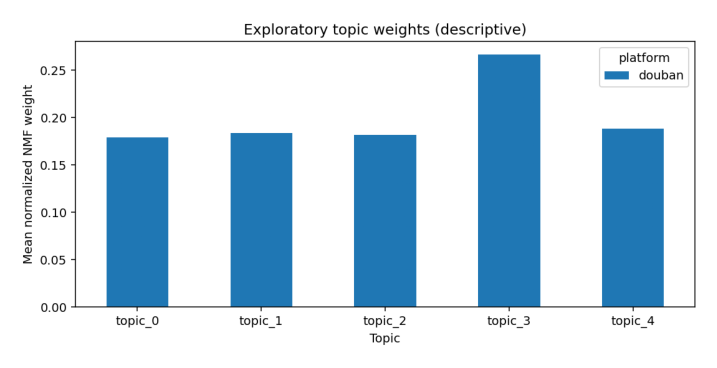

In [2]:
topics = pd.read_csv(root/'results/demo/topics.csv')
print('SYNTHETIC DEMO ONLY')
print(topics.to_string(index=False))
image = plt.imread(root/'results/demo/topic_shares.png')
fig, ax = plt.subplots(figsize=(9,5)); ax.imshow(image); ax.axis('off')
plt.show()

## 3. Synthetic lexicon indicators

The new lexicons are explicit in analysis.py. They do not reconstruct the original report's dictionaries. Activation rate is the share of texts containing a lexicon item. Zero rate is its complement. Occurrence does not imply agreement, hostility or a person's underlying attitude.

In [3]:
print('SYNTHETIC DEMO ONLY')
print(pd.read_csv(root/'results/demo/frame_summary.csv').round(4).to_string(index=False))

SYNTHETIC DEMO ONLY
platform             frame  documents  activation_rate  zero_rate  mean_hits_per_100_chinese_chars
  douban      gender_roles         60              0.2        0.8                           1.7691
  douban conflict_language         60              0.2        0.8                           1.1251
  douban        asset_risk         60              0.2        0.8                           1.9845


## 4. Observed data: aggregate audit and descriptive indicators

This section reads **saved aggregates**, not the raw posts. The supplied file contains 363 records in 142 topics. Normalization and duplicate removal retain 346 texts in 137 topics. These counts differ from the report's complete corpus. Fourteen source records were marked as main posts; the rest were marked as replies.

The indicator rates use the new, illustrative lexicons in this repository. They describe the retained subset only and are neither a replication of the report nor a platform comparison. The code was executed privately on the supplied input; raw texts and extracted topic vocabulary remain excluded.

{
  "data_kind": "observed_aggregate_only",
  "audit": {
    "input_rows": 363,
    "input_threads": 142,
    "short_or_empty_removed": 0,
    "normalized_duplicates_removed": 17,
    "retained_rows": 346,
    "retained_threads": 137,
    "platform_count": 1
  },
  "classification_status": {
    "status": "not_run",
    "reason": "Requires exactly two observed platforms; no labels are fabricated."
  },
  "note": "Source-file subset only; not the full corpus from the course report."
}
platform             frame  documents  activation_rate  zero_rate  mean_hits_per_100_chinese_chars
  douban      gender_roles        346           0.2283     0.7717                           0.5976
  douban conflict_language        346           0.0173     0.9827                           0.0371
  douban        asset_risk        346           0.0607     0.9393                           0.0773


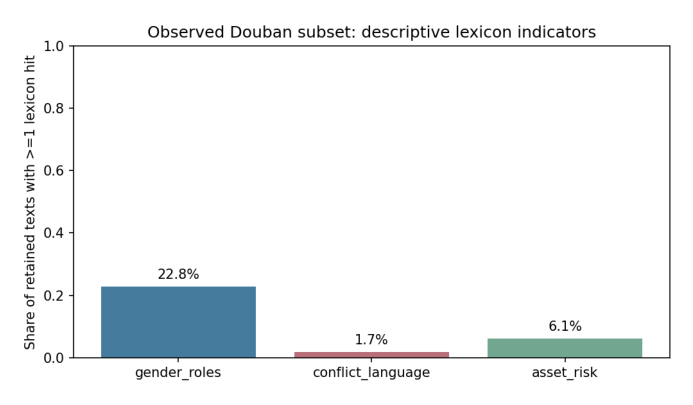

In [4]:
print(json.dumps(json.loads((root/'observed_data_audit.json').read_text()), indent=2))
print(pd.read_csv(root/'results/observed_frame_summary.csv').round(4).to_string(index=False))
image = plt.imread(root/'figures/observed_frame_activation.png')
fig, ax = plt.subplots(figsize=(9,5)); ax.imshow(image); ax.axis('off')
plt.show()

## 5. Optional private analysis and limitations

With an authorized CSV stored at `private/corpus.csv`, run:

```bash
python analysis.py --input private/corpus.csv --output private/results
```

The CSV requires `text` and `topic_id` or `thread_id`. An optional platform label defaults to Douban. Two observed platforms enable fixed logistic regression and majority-baseline evaluation with thread-disjoint splitting; one platform cannot support that task.

Sampling keywords, title filtering, collection quotas and group membership can shape the corpus. Platform membership does not identify gender. Lexicon hits ignore negation and sarcasm; NMF requires substantive validation. Full-text cleaning is not sufficient anonymization. No statistical significance or causal effects are asserted. See METHODS.md for next steps.

**Acknowledgment:** original supplied materials and course report by Dingyu Zhang; AI-assisted refactoring, documentation and new illustrative demo/lexicons. Libraries: jieba, scikit-learn, pandas, NumPy, Matplotlib and Beautiful Soup.